In [54]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from IPython.display import display

In [55]:
df = pd.read_csv('VLagun_Total_Basins_DT.csv')
display(df.head())

,PSU,O2,temp.,SS,SRP,DOP,PP,NH4N,NO3N,DON,...,Acartia tonsa,Eurytemora affinis,Cyclops sp.,Nauplii Cyclopoida,Nauplii Calanoida,Filinia longiseta,Keratella cochlearis cochlearis,Keratella cochlearis f.tecta,Keratella quadrata,Basin
0,3.757624,9.46,18.3,52.0,3.5,11.7,185.0,0.039,0.022,0.551,...,0.9298,0.9251,0.0000,0.0025,0.0257,1.3152,0.8920,0.2714,0.0000,Eastern
1,3.504707,9.89,19.1,50.0,4.4,17.5,111.3,0.020,0.025,0.123,...,0.0378,0.0000,0.0000,0.0000,0.0000,0.0769,0.0640,0.0464,0.0000,Eastern
2,3.721493,9.63,17.5,62.0,11.7,13.0,117.6,0.036,0.021,0.727,...,0.0000,0.0000,0.0093,0.0138,0.0006,0.0466,0.0120,0.0044,0.0000,Eastern
3,4.407982,9.54,18.4,55.0,7.4,16.2,124.7,0.023,0.024,0.566,...,0.0000,0.0129,0.0060,0.0140,0.0155,0.0313,0.0079,0.0040,0.0000,Eastern
4,4.389916,9.34,17.8,53.0,13.8,21.4,84.4,0.031,0.030,0.022,...,0.0000,0.0141,0.0000,0.0093,0.0007,0.0491,0.0143,0.0019,0.0026,Eastern


In [56]:
# Zamiana klas z tekstu na wartości numeryczne: Western -> 1, Eastern -> 0
df['Basin'] = [1 if i == "Western" else 0 for i in df['Basin']]

# Zdefiniowanie zmiennych objaśniających (X) i zmiennej docelowej (y)
X = df.drop("Basin", axis=1)
y = df["Basin"]

# Podział na zbiór treningowy (70%) i testowy (30%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

print('#Training data points: %d' % X_train.shape[0])
print('#Testing data points: %d' % X_test.shape[0])
print('Class:', np.unique(y))

#Training data points: 108
#Testing data points: 47
Class: [0 1]


In [57]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Inicjalizacja i trening modelu drzewa decyzyjnego
tree = DecisionTreeClassifier(criterion='entropy', 
                              max_depth=3, 
                              min_samples_leaf=5, 
                              random_state=0)
tree.fit(X_train, y_train)

# Ewaluacja na zbiorze testowym
y_pred_test = tree.predict(X_test)
print('Test dataset Accuracy (tree): %.2f' % accuracy_score(y_test, y_pred_test))

# Ewaluacja na zbiorze treningowym
y_pred_train = tree.predict(X_train)
print('Train dataset Accuracy (tree): %.2f' % accuracy_score(y_train, y_pred_train))

Test dataset Accuracy (tree): 0.72
Train dataset Accuracy (tree): 0.81


In [58]:
from sklearn.tree import export_graphviz

dot_data = export_graphviz(
    tree,
    out_file=None, 
    feature_names=X.columns.values,
    class_names=['Eastern', 'Western'],
    filled=True,
    rounded=True
)
print(dot_data)


#kod z konsoli wklejamy do http://www.webgraphviz.com/


digraph Tree {
node [shape=box, style="filled, rounded", color="black", fontname="helvetica"] ;
edge [fontname="helvetica"] ;
0 [label="Cyclops sp. <= 0.072\nentropy = 0.975\nsamples = 108\nvalue = [64, 44]\nclass = Eastern", fillcolor="#f7d8c1"] ;
1 [label="Depth <= 1.95\nentropy = 0.881\nsamples = 90\nvalue = [63.0, 27.0]\nclass = Eastern", fillcolor="#f0b78e"] ;
0 -> 1 [labeldistance=2.5, labelangle=45, headlabel="True"] ;
2 [label="entropy = 0.0\nsamples = 7\nvalue = [0, 7]\nclass = Western", fillcolor="#399de5"] ;
1 -> 2 ;
3 [label="SS <= 68.75\nentropy = 0.797\nsamples = 83\nvalue = [63, 20]\nclass = Eastern", fillcolor="#eda978"] ;
1 -> 3 ;
4 [label="entropy = 0.0\nsamples = 21\nvalue = [21, 0]\nclass = Eastern", fillcolor="#e58139"] ;
3 -> 4 ;
5 [label="entropy = 0.907\nsamples = 62\nvalue = [42, 20]\nclass = Eastern", fillcolor="#f1bd97"] ;
3 -> 5 ;
6 [label="Nauplii Cyclopoida <= 0.104\nentropy = 0.31\nsamples = 18\nvalue = [1, 17]\nclass = Western", fillcolor="#45a3e7"] ;
0 

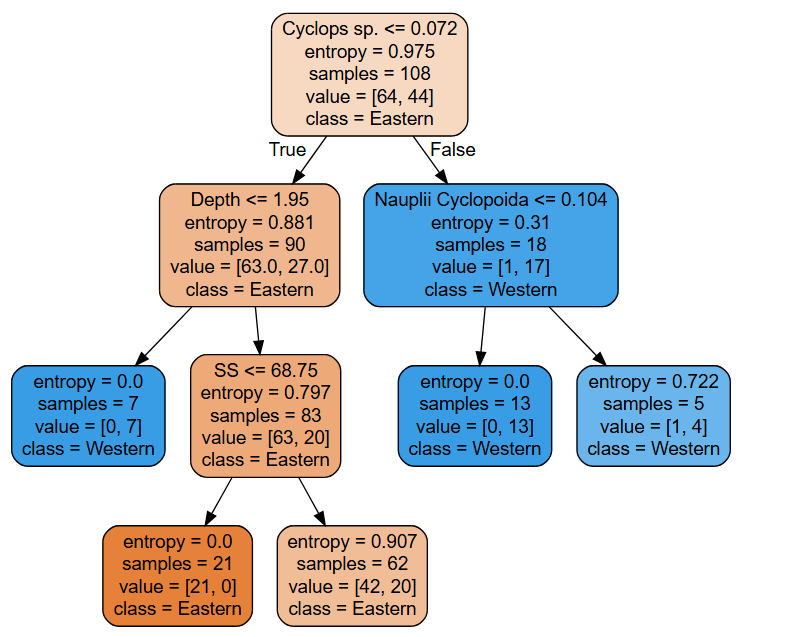

In [59]:
from IPython.display import Image, display

display(Image(filename="img.png"))

Test dataset Accuracy (forest): 0.7660
Train dataset Accuracy (forest): 1.0000

Hierarchia ważności cech (Top 10):
 1) Nauplii Cyclopoida             0.087723
 2) Cyclops sp.                    0.072056
 3) Depth                          0.068339
 4) DON                            0.053796
 5) PSU                            0.042186
 6) DOP                            0.037714
 7) O2                             0.036068
 8) DOC                            0.035916
 9) Cyanobacteria                  0.031511
10) Acartia tonsa                  0.029091


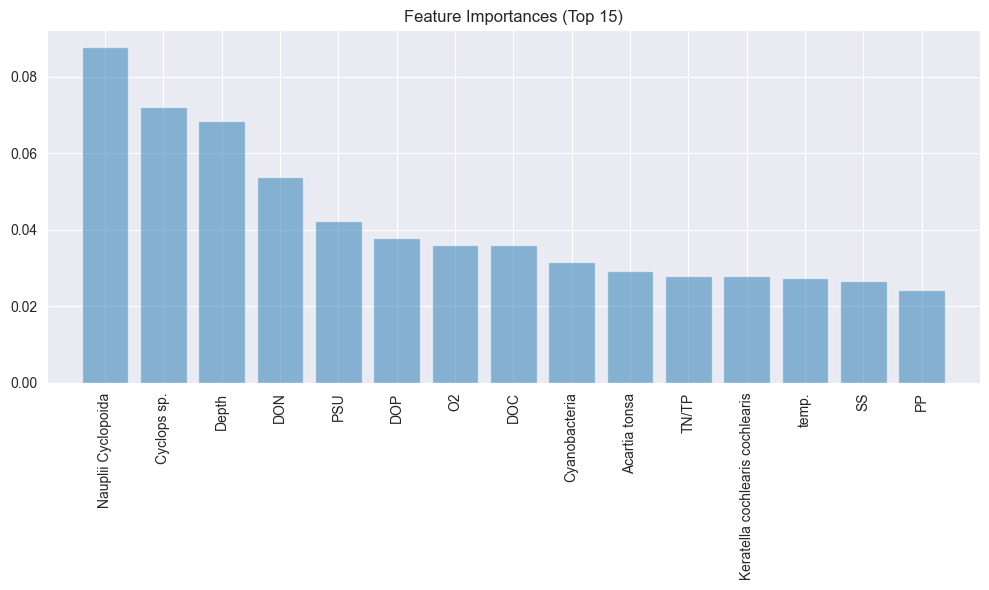

In [60]:
from matplotlib import pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# Inicjalizacja i trening modelu lasu losowego
forest = RandomForestClassifier(criterion='entropy',
                                n_estimators=200,
                                random_state=1,
                                n_jobs=2)
forest.fit(X_train, y_train)

print('Test dataset Accuracy (forest): %.4f' % accuracy_score(y_test, forest.predict(X_test)))
print('Train dataset Accuracy (forest): %.4f' % accuracy_score(y_train, forest.predict(X_train)))

# Pobranie ważności cech i ich posortowanie
importances = forest.feature_importances_
indices = np.argsort(importances)[::-1]

print("\nHierarchia ważności cech (Top 10):")
for f in range(10): # Wyświetlamy 10 najważniejszych
    print("%2d) %-*s %f" % (f + 1, 30, X.columns.values[indices[f]], importances[indices[f]]))

# Wykres ważności cech (Top 15 dla czytelności)
top_n = 15
plt.figure(figsize=(10, 6))
plt.title('Feature Importances (Top 15)')
plt.bar(range(top_n), importances[indices[:top_n]], align='center', alpha=0.5)
plt.xticks(range(top_n), X.columns.values[indices[:top_n]], rotation=90)
plt.xlim([-1, top_n])
plt.tight_layout()
plt.show()

Najważniejsze cechy wybrane do analizy przestrzennej: Nauplii Cyclopoida oraz Cyclops sp.


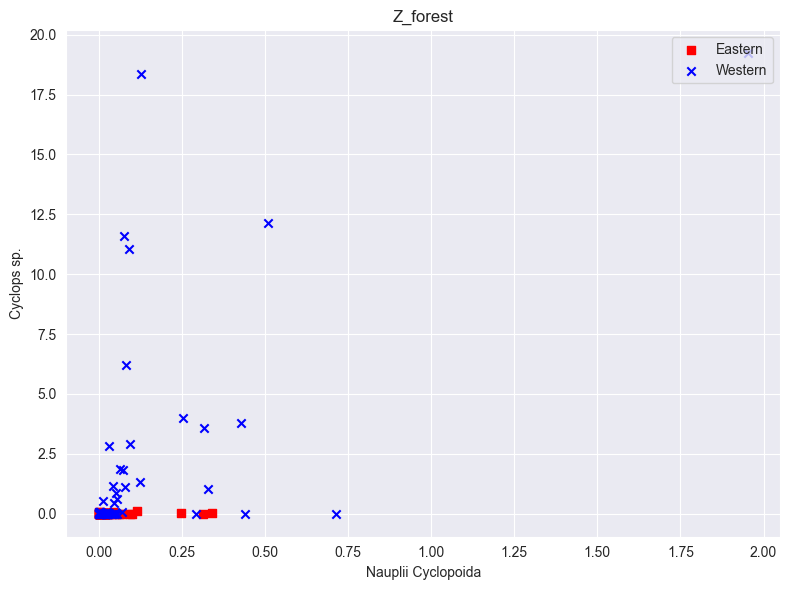

In [61]:
# Automatyczne pobranie nazw 2 najważniejszych cech z modelu Random Forest
feature1 = X.columns.values[indices[0]]
feature2 = X.columns.values[indices[1]]
print(f"Najważniejsze cechy wybrane do analizy przestrzennej: {feature1} oraz {feature2}")

# Przygotowanie danych 2D
Z_forest = X[[feature1, feature2]].values
Z_forest_train, Z_forest_test, y_forest_train, y_forest_test = train_test_split(
    Z_forest, y, test_size=0.3, random_state=0)

# Rozkład w klasach dwóch najważniejszych cech
colors = ['r', 'b']
markers = ['s', 'x']

plt.figure(figsize=(8, 6))
for l, c, m in zip(np.unique(y.values), colors, markers):
    plt.scatter(Z_forest[y.values == l, 0],
                Z_forest[y.values == l, 1],
                c=c, label='Western' if l==1 else 'Eastern', marker=m)

plt.title('Z_forest')
plt.xlabel(feature1)
plt.ylabel(feature2)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

Test dataset Accuracy (tree_forest): 0.68


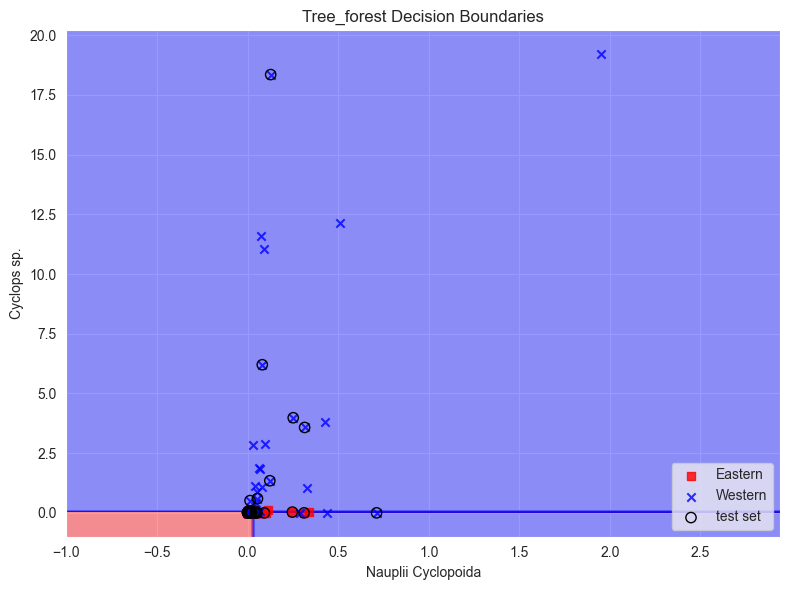

Test dataset Accuracy (forest_forest): 0.72


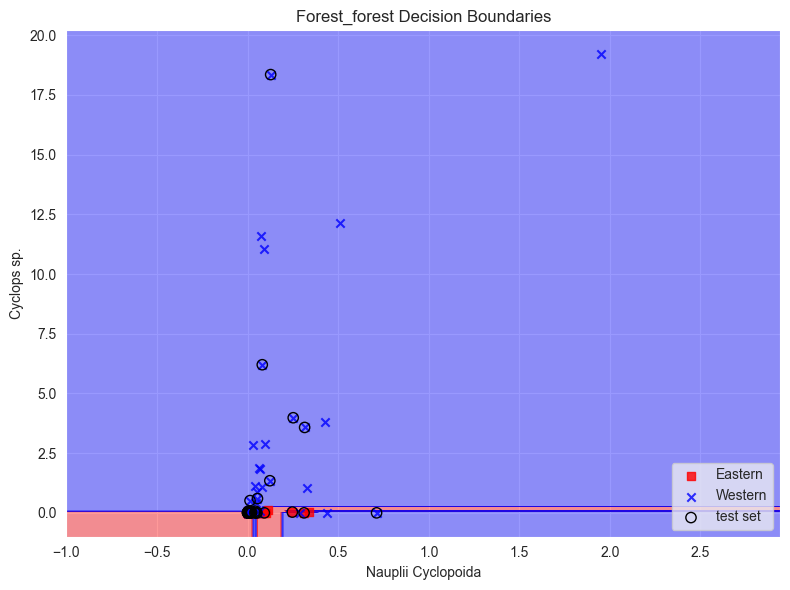

In [62]:
from matplotlib.colors import ListedColormap

def plot_decision_regions(X, y, classifier, test_idx=None, resolution=0.02):
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))

    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)
    plt.contourf(xx1, xx2, Z, alpha=0.4, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, 0], y=X[y == cl, 1],
                    alpha=0.8, c=[cmap(idx)],
                    marker=markers[idx], label='Western' if cl==1 else 'Eastern')

    if test_idx:
        X_test, y_test = X[test_idx, :], y[test_idx]
        plt.scatter(X_test[:, 0], X_test[:, 1], c='none', alpha=1.0,
                    linewidths=1, marker='o', s=55, label='test set', edgecolors='k')

# Połączenie danych do wykresu
Z_forest_combined = np.vstack((Z_forest_train, Z_forest_test))
y_forest_combined = np.hstack((y_forest_train, y_forest_test))
test_idx_range = range(y_forest_train.shape[0], y_forest_train.shape[0] + y_forest_test.shape[0])

# --- MODEL 1: Drzewo Decyzyjne na 2 cechach (Tree_forest) ---
tree_forest = DecisionTreeClassifier(criterion='entropy', max_depth=10, min_samples_leaf=5, random_state=0)
tree_forest.fit(Z_forest_train, y_forest_train)
print('Test dataset Accuracy (tree_forest): %.2f' % accuracy_score(y_forest_test, tree_forest.predict(Z_forest_test)))

plt.figure(figsize=(8, 6))
plot_decision_regions(Z_forest_combined, y_forest_combined, classifier=tree_forest, test_idx=test_idx_range)
plt.title('Tree_forest Decision Boundaries')
plt.xlabel(feature1)
plt.ylabel(feature2)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# --- MODEL 2: Las Losowy na 2 cechach (Forest_forest) ---
forest_forest = RandomForestClassifier(criterion='entropy', n_estimators=200, random_state=1, n_jobs=2)
forest_forest.fit(Z_forest_train, y_forest_train)
print('Test dataset Accuracy (forest_forest): %.2f' % accuracy_score(y_forest_test, forest_forest.predict(Z_forest_test)))

plt.figure(figsize=(8, 6))
plot_decision_regions(Z_forest_combined, y_forest_combined, classifier=forest_forest, test_idx=test_idx_range)
plt.title('Forest_forest Decision Boundaries')
plt.xlabel(feature1)
plt.ylabel(feature2)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()